In [15]:
import scanpy as sc
import pandas as pd
import numpy as np

# Load the Stage 18 
practicedata = sc.read_h5ad("Stage18_Data.h5ad")

In [2]:
adata_pax6_wt = practicedata[practicedata.obs['orig.ident'] == 'pax6_WT'].copy()
adata_pax6_mut = practicedata[practicedata.obs['orig.ident'] == 'pax6_Mutant'].copy()

In [3]:
adata_pax6_wt_6_9 = adata_pax6_wt[
    adata_pax6_wt.obs['seurat_clusters'].isin([6, 9])
].copy()

adata_pax6_mut_6_9 = adata_pax6_mut[
    adata_pax6_mut.obs['seurat_clusters'].isin([6, 9])
].copy()


In [6]:
import os
import os.path as op
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import bobaT as bb

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
import warnings
warnings.filterwarnings('ignore')

In [19]:
import scanpy as sc
import seaborn as sns
import pandas as pd
import numpy as np


OUTPUT_DIR = "./output"
RUN_DIR = op.join(OUTPUT_DIR, "stage18_wt_all_tfs")
VAL_DIR = op.join(RUN_DIR, "validation")
os.makedirs(RUN_DIR, exist_ok=True)

In [7]:
# Input data
DATA_DIR = "./test_data"

# Output directories
OUTPUT_DIR = "./output"
VAL_DIR = "./output/validation"
ATTRACTOR_DIR = "./output/attractors"
PERTURB_DIR = "./output/perturbations"

os.makedirs(OUTPUT_DIR, exist_ok=True)

tfs = [
    "ACCS", "ADNP", "ADNP2", "AEBP2", "AHR", "AHRR", "ALX1", "ALX4", "AR", "ARID1A",
    "ARID1B", "ARID2", "ARID3A", "ARID3B", "ARID4A", "ARID4B", "ARID5B", "ARNT", "ARNT2", "ARX",
    "ASCL1", "ASCL2", "ATF1", "ATF2", "ATF3", "ATF4", "ATF5", "ATF6", "ATF6B", "ATF7",
    "ATOH1", "ATOH8", "BACH1", "BACH2", "BARHL1", "BARHL2", "BARX2", "BATF", "BBX", "BCL11A",
    "BCL11B", "BCL6", "BHLHA9", "BHLHE22", "BHLHE40", "BHLHE41", "BNC2", "CAMTA1", "CAMTA2", "CARHSP1",
    "CDC5L", "CDX1", "CDX2", "CDX4", "CEBPA", "CEBPB", "CEBPD", "CEBPE", "CEBPG", "CHAMP1",
    "CIC", "CLIP4", "CLOCK", "CREB1", "CREB3", "CREB3L1", "CREB3L2", "CREB3L4", "CREB5", "CREBL2",
    "CREBRF", "CREBZF", "CREM", "CRX", "CSDE1", "CTCF", "CUX1", "CUX2", "DBP", "DBX1",
    "DBX2", "DDIT3", "DEAF1", "DIAPH2", "DLX1", "DLX2", "DLX3", "DLX4", "DLX5", "DLX6",
    "DMBX1", "DMRT1", "DMRT2", "DMRT3", "DMRTA1", "DMRTA2", "DMTF1", "DNAJC1", "DNAJC2", "DNAJC21",
    "DYNC2H1", "E2F1", "E2F3", "E2F4", "E2F5", "E2F6", "E2F7", "E2F8", "E4F1", "EBF2",
    "EBF3", "EDF1", "EGR1", "EGR2", "EHF", "ELF1", "ELF2", "ELF3", "ELK1", "ELK3",
    "ELK4", "EMX1", "EMX2", "EN1", "EN2", "EOMES", "EP400", "EPAS1", "ERF", "ERG",
    "ESR1", "ESR2", "ESRRA", "ESRRB", "ESRRG", "ETS1", "ETS2", "ETV1", "ETV2", "ETV3",
    "ETV3L", "ETV4", "ETV6", "EVX1", "FEZF1", "FEZF2", "FLI1", "FOS", "FOSL2", "FOXA1",
    "FOXA2", "FOXB1", "FOXC1", "FOXC2", "FOXD1", "FOXD2", "FOXD3", "FOXF1", "FOXG1", "FOXH1",
    "FOXI1", "FOXI2", "FOXJ1", "FOXJ2", "FOXJ3", "FOXK2", "FOXM1", "FOXN1", "FOXN2", "FOXN3",
    "FOXN4", "FOXO1", "FOXO3", "FOXO4", "FOXO6", "FOXP1", "FOXP2", "FOXP3", "FOXP4", "FOXQ1",
    "FOXR1", "GABPA", "GATA1", "GATA2", "GATA3", "GATA4", "GATA5", "GATA6", "GATAD1", "GATAD2A",
    "GATAD2B", "GBX2", "GCC1", "GCM1", "GFI1", "GFI1B", "GLI1", "GLI2", "GLI3", "GLIS1",
    "GLIS2", "GLIS3", "GMEB1", "GMEB2", "GPBP1", "GPBP1L1", "GRHL1", "GRHL2", "GRHL3", "GSC",
    "GSX1", "GSX2", "GTF2I", "GTF2IRD1", "GTF3A", "GZF1", "HAND1", "HAND2", "HBP1", "HDX",
    "HELT", "HES1", "HES2", "HES4", "HES5", "HES6", "HES7", "HESX1", "HEY1", "HEY2",
    "HHEX", "HIC1", "HIC2", "HIF1A", "HINFP", "HIVEP1", "HIVEP2", "HIVEP3", "HLF", "HMBOX1",
    "HMG20A", "HMG20B", "HMGB1", "HMGB2", "HMGB3", "HMGXB3", "HMGXB4", "HMX1", "HMX2", "HMX3",
    "HNF1A", "HNF1B", "HNF4A", "HNF4G", "HOMEZ", "HOPX", "HOXA1", "HOXA11", "HOXA13", "HOXA2",
    "HOXA3", "HOXA4", "HOXA6", "HOXA7", "HOXA9", "HOXB1", "HOXB2", "HOXB3", "HOXB5", "HOXB6",
    "HOXB7", "HOXB8", "HOXB9", "HOXC10", "HOXC11", "HOXC13", "HOXC4", "HOXC5", "HOXC6", "HOXC8",
    "HOXC9", "HOXD1", "HOXD10", "HOXD3", "HOXD4", "HOXD8", "HOXD9", "HSF1", "HSF2", "HSF4",
    "HSF5", "ID2", "ID3", "ID4", "IKZF1", "IKZF2", "IKZF4", "IKZF5", "INSM1", "IRF1",
    "IRF2", "IRF3", "IRF5", "IRF6", "IRF7", "IRF8", "IRF9", "IRX1", "IRX2", "IRX3",
    "IRX4", "IRX5", "ISL1", "ISL2", "JARID2", "JUN", "JUNB", "JUND", "KAT7", "KDM5A",
    "KDM5B", "KDM5C", "KLF10", "KLF11", "KLF12", "KLF13", "KLF15", "KLF17", "KLF3", "KLF4",
    "KLF5", "KLF6", "KLF7", "KLF8", "KLF9", "KMT2C", "KMT2D", "L3MBTL1", "L3MBTL3", "LCOR",
    "LCORL", "LEF1", "LHX1", "LHX2", "LHX3", "LHX5", "LHX6", "LHX8", "LHX9", "LIN28A",
    "LIN28B", "LMX1A", "LMX1B", "LYL1", "MAF", "MAFB", "MAFF", "MAFG", "MAFK", "MAX",
    "MAZ", "MECOM", "MEF2A", "MEF2C", "MEF2D", "MEIS1", "MEIS2", "MEIS3", "MEOX2", "MGA",
    "MIER1", "MIER2", "MIER3", "MIS18BP1", "MITF", "MKX", "MLX", "MLXIP", "MLXIPL", "MNT",
    "MSANTD2", "MSANTD3", "MSANTD4", "MSGN1", "MSX1", "MSX2", "MTA1", "MTA2", "MTF1", "MXD1",
    "MXD3", "MXD4", "MXI1", "MYB", "MYBL1", "MYBL2", "MYBPC1", "MYC", "MYCL", "MYCN",
    "MYF5", "MYNN", "MYOG", "MYPOP", "MYRF", "MYRFL", "MYSM1", "MYT1", "MYT1L", "NAIF1",
    "NCOA3", "NCOR1", "NCOR2", "NEUROD1", "NEUROD2", "NEUROD4", "NEUROG2", "NEUROG3", "NFAT5", "NFATC1",
    "NFATC2", "NFATC3", "NFE2", "NFE2L1", "NFE2L2", "NFE2L3", "NFIB", "NFIC", "NFIL3", "NFIX",
    "NFKB1", "NFKB2", "NFX1", "NFXL1", "NFYA", "NHLH1", "NKX1-2", "NKX2-1", "NKX2-2", "NKX2-3",
    "NKX2-4", "NKX2-5", "NKX2-8", "NKX3-1", "NKX6-1", "NKX6-2", "NKX6-3", "NPAS2", "NPAS3", "NR1D1",
    "NR1D2", "NR1H2", "NR1H4", "NR1I2", "NR2C1", "NR2C2", "NR2E1", "NR2F1", "NR2F2", "NR2F6",
    "NR3C1", "NR3C2", "NR4A1", "NR4A2", "NR4A3", "NR5A1", "NR5A2", "NR6A1", "NRBF2", "NRF1",
    "NRIP3", "NRL", "OLIG2", "OLIG3", "ONECUT1", "ONECUT2", "ONECUT3", "OSR1", "OSR2", "OTP",
    "OTX1", "OTX2", "OVOL1", "OVOL2", "OVOL3", "PAICS", "PASD1", "PATZ1", "PAX2", "PAX3",
    "PAX5", "PAX6", "PAX7", "PAX8", "PAX9", "PBRM1", "PBX1", "PBX2", "PBX3", "PGR",
    "PHOX2B", "PITX1", "PITX2", "PITX3", "PKNOX1", "PKNOX2", "PLAG1", "PMS1", "POU2F1", "POU2F2",
    "POU2F3", "POU3F1", "POU3F2", "POU3F3", "POU3F4", "POU4F1", "POU6F1", "PPARA", "PPARD", "PPARG",
    "PRDM1", "PRDM10", "PRDM12", "PRDM13", "PRDM14", "PRDM15", "PRDM16", "PRDM2", "PRDM4", "PRDM5",
    "PRDM6", "PRDM8", "PROX1", "PRRX1", "PRRX2", "PTF1A", "RAD54B", "RARA", "RARB", "RARG",
    "RAX", "RAX2", "RBPJ", "RCOR1", "RCOR2", "RCOR3", "REL", "RELA", "RELB", "RERE",
    "REST", "RFX1", "RFX2", "RFX3", "RFX4", "RFX5", "RFX6", "RFX7", "RLF", "RORA",
    "RORB", "RORC", "RREB1", "RUNX1", "RUNX2", "RXRA", "RXRB", "RXRG", "SALL1", "SALL2",
    "SALL3", "SALL4", "SAMD11", "SATB1", "SATB2", "SCX", "SEBOX", "SGSM2", "SHOX", "SIM1",
    "SIX1", "SIX2", "SIX3", "SIX4", "SIX6", "SMAD1", "SMAD2", "SMAD3", "SMAD6", "SMAD7",
    "SMAD9", "SMARCA1", "SMARCA5", "SMARCC1", "SMARCC2", "SMARCE1", "SNAI1", "SNAI2", "SNAI3", "SNAPC4",
    "SOX1", "SOX10", "SOX11", "SOX13", "SOX15", "SOX17", "SOX18", "SOX2", "SOX21", "SOX3",
    "SOX4", "SOX5", "SOX6", "SOX7", "SOX8", "SOX9", "SP1", "SP110", "SP2", "SP3",
    "SP4", "SP5", "SP6", "SP7", "SP8", "SP9", "SPDEF", "SPI1", "SPIB", "SPIC",
    "SREBF1", "SREBF2", "SRF", "SSRP1", "ST18", "STAT1", "STAT2", "STAT3", "STAT4", "STAT5B",
    "STAT6", "STOX1", "STOX2", "SUB1", "SYCP2", "SYMPK", "TADA2A", "TADA2B", "TAL1", "TAL2",
    "TBR1", "TBX1", "TBX15", "TBX2", "TBX20", "TBX21", "TBX3", "TBX4", "TBX5", "TBX6",
    "TCF12", "TCF15", "TCF21", "TCF3", "TCF4", "TCF7", "TCF7L1", "TCF7L2", "TCFL5", "TEF",
    "TERF1", "TERF2", "TFAM", "TFAP2A", "TFAP2B", "TFAP2C", "TFAP2D", "TFAP2E", "TFAP4", "TFCP2",
    "TFCP2L1", "TFDP1", "TFDP2", "TFEC", "TGIF1", "TGIF2", "THAP1", "THAP11", "THAP2", "THAP4",
    "THAP5", "THAP7", "THRA", "THRB", "TLX1", "TLX3", "TOX", "TOX2", "TOX3", "TOX4",
    "TP53", "TP63", "TP73", "TRERF1", "TSHZ1", "TSHZ2", "TSHZ3", "TSNARE1", "TTF1", "TUB",
    "TULP1", "TULP2", "TULP3", "TULP4", "TUT1", "TWIST1", "TWIST2", "UBP1", "UBTF", "UNCX",
    "USF1", "USF2", "USF3", "USH2A", "VAX1", "VAX2", "VDR", "VEZF1", "VSX1", "VSX2",
    "WDHD1", "WIZ", "WT1", "XBP1", "YBX1", "YBX2", "YOD1", "YY1", "ZBED1", "ZBED4",
    "ZBTB1", "ZBTB10", "ZBTB11", "ZBTB12", "ZBTB14", "ZBTB16", "ZBTB17", "ZBTB18", "ZBTB2", "ZBTB20",
    "ZBTB21", "ZBTB22", "ZBTB24", "ZBTB25", "ZBTB26", "ZBTB3", "ZBTB33", "ZBTB34", "ZBTB37", "ZBTB39",
    "ZBTB40", "ZBTB41", "ZBTB43", "ZBTB44", "ZBTB45", "ZBTB46", "ZBTB47", "ZBTB48", "ZBTB49", "ZBTB5",
    "ZBTB6", "ZBTB7B", "ZBTB7C", "ZBTB8A", "ZBTB8B", "ZBTB9", "ZC2HC1A", "ZC2HC1C", "ZEB1", "ZEB2",
    "ZFAT", "ZFHX2", "ZFHX3", "ZFHX4", "ZFP64", "ZFP91", "ZFPM1", "ZFPM2", "ZFX", "ZHX1",
    "ZHX2", "ZHX3", "ZIC2", "ZIC3", "ZIC4", "ZIC5", "ZNF142", "ZNF143", "ZNF148", "ZNF160",
    "ZNF217", "ZNF219", "ZNF236", "ZNF250", "ZNF276", "ZNF277", "ZNF281", "ZNF292", "ZNF319", "ZNF326",
    "ZNF329", "ZNF335", "ZNF341", "ZNF362", "ZNF366", "ZNF367", "ZNF383", "ZNF384", "ZNF407", "ZNF408",
    "ZNF410", "ZNF414", "ZNF423", "ZNF438", "ZNF469", "ZNF474", "ZNF507", "ZNF516", "ZNF518A", "ZNF518B",
    "ZNF521", "ZNF526", "ZNF532", "ZNF534", "ZNF536", "ZNF554", "ZNF574", "ZNF592", "ZNF605", "ZNF618",
    "ZNF622", "ZNF628", "ZNF639", "ZNF644", "ZNF646", "ZNF652", "ZNF653", "ZNF668", "ZNF684", "ZNF687",
    "ZNF710", "ZNF711", "ZNF740", "ZNF770", "ZNF800", "ZNF821", "ZNF827", "ZNF831", "ZNF865", "ZXDC",
    "ZZZ3",
]

tfs = [tf.upper() for tf in tfs]
print("Number of candidate genes:", len(tfs))

Number of candidate genes: 861


In [8]:
G = bb.net.make_network(
    tfs,
    outdir=OUTPUT_DIR,
    network_name="chea_network",
    save_unfiltered=True,     # Save the network before pruning
    do_prune=True,            # Apply source/sink pruning
    prune_sources=True,       # Remove nodes with no incoming edges
    prune_sinks=True,         # Remove nodes with no outgoing edges
    do_prune_info=True,       # Filter by database support
    do_prune_to_chea=True,    # Keep edges with ChEA support
    prune_self_loops=True,    # Remove self-regulation edges during filtering
)

print(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

ACCS
ADNP
ADNP2
AEBP2
AHR
AHRR
ALX1
ALX4
AR
ARID1A
ARID1B
ARID2
ARID3A
ARID3B
ARID4A
ARID4B
ARID5B
ARNT
ARNT2
ARX
ASCL1
ASCL2
ATF1
ATF2
ATF3
ATF4
ATF5
ATF6
ATF6B
ATF7
ATOH1
ATOH8
BACH1
BACH2
BARHL1
BARHL2
BARX2
BATF
BBX
BCL11A
BCL11B
BCL6
BHLHA9
BHLHE22
BHLHE40
BHLHE41
BNC2
CAMTA1
CAMTA2
CARHSP1
CDC5L
CDX1
CDX2
CDX4
CEBPA
CEBPB
CEBPD
CEBPE
CEBPG
CHAMP1
CIC
CLIP4
CLOCK
CREB1
CREB3
CREB3L1
CREB3L2
CREB3L4
CREB5
CREBL2
CREBRF
CREBZF
CREM
CRX
CSDE1
CTCF
CUX1
CUX2
DBP
DBX1
DBX2
DDIT3
DEAF1
DIAPH2
DLX1
DLX2
DLX3
DLX4
DLX5
DLX6
DMBX1
DMRT1
DMRT2
DMRT3
DMRTA1
DMRTA2
DMTF1
DNAJC1
DNAJC2
DNAJC21
DYNC2H1
E2F1
E2F3
E2F4
E2F5
E2F6
E2F7
E2F8
E4F1
EBF2
EBF3
EDF1
EGR1
EGR2
EHF
ELF1
ELF2
ELF3
ELK1
ELK3
ELK4
EMX1
EMX2
EN1
EN2
EOMES
EP400
EPAS1
ERF
ERG
ESR1
ESR2
ESRRA
ESRRB
ESRRG
ETS1
ETS2
ETV1
ETV2
ETV3
ETV3L
ETV4
ETV6
EVX1
FEZF1
FEZF2
FLI1
FOS
FOSL2
FOXA1
FOXA2
FOXB1
FOXC1
FOXC2
FOXD1
FOXD2
FOXD3
FOXF1
FOXG1
FOXH1
FOXI1
FOXI2
FOXJ1
FOXJ2
FOXJ3
FOXK2
FOXM1
FOXN1
FOXN2
FOXN3
FOXN4
FOXO1
FOXO3
FOXO4
FOXO6

In [10]:
for level in ["unfiltered", "pruned", "high_evidence", "chea"]:
    path = op.join(OUTPUT_DIR, f"chea_network_{level}.csv")
    if op.exists(path) and os.path.getsize(path) > 0:
        edges = pd.read_csv(path, header=None, names=["source", "target"])
        n_nodes = len(set(edges["source"]) | set(edges["target"]))
        print(level, n_nodes, "nodes and", len(edges), "edges")
    else:
        print(level, "was empty or was not written")

unfiltered 848 nodes and 27328 edges
pruned 210 nodes and 8095 edges
high_evidence 24 nodes and 66 edges
chea 24 nodes and 66 edges


In [11]:
network_file = op.join(OUTPUT_DIR, 'chea_network_pruned.csv')
graph, vertex_dict = bb.load.load_network(
    network_file,
    remove_sinks=False,
    remove_selfloops=False,
    remove_sources=False,
)
v_names, nodes = bb.utils.get_nodes(vertex_dict, graph)
print(len(nodes), 'nodes:', sorted(nodes))

210 nodes: ['AHR', 'AR', 'ARID3A', 'ARNT', 'ATF1', 'ATF2', 'ATF3', 'ATF4', 'BACH1', 'BCL11B', 'BCL6', 'CDX2', 'CEBPA', 'CEBPB', 'CEBPD', 'CEBPE', 'CLOCK', 'CREB1', 'CREM', 'CRX', 'CTCF', 'CUX1', 'DMRT1', 'DNAJC2', 'E2F1', 'E2F4', 'E2F6', 'EGR1', 'ELF1', 'ELF3', 'ELK1', 'ELK4', 'EOMES', 'ERG', 'ESR1', 'ESR2', 'ESRRB', 'ETS1', 'ETS2', 'ETV4', 'FLI1', 'FOS', 'FOXA1', 'FOXA2', 'FOXC1', 'FOXD1', 'FOXF1', 'FOXJ1', 'FOXM1', 'FOXO1', 'FOXO3', 'FOXP1', 'FOXP2', 'FOXP3', 'GABPA', 'GATA1', 'GATA2', 'GATA3', 'GATA4', 'GATA6', 'GBX2', 'GFI1', 'GFI1B', 'GLI2', 'GTF2I', 'HIF1A', 'HINFP', 'HIVEP1', 'HLF', 'HNF1A', 'HNF1B', 'HNF4A', 'HOXA2', 'HOXC9', 'HOXD9', 'HSF1', 'IKZF1', 'IRF1', 'IRF2', 'IRF7', 'IRF8', 'IRF9', 'JARID2', 'JUN', 'JUND', 'KDM5B', 'KLF11', 'KLF13', 'KLF4', 'KLF5', 'LEF1', 'LYL1', 'MAX', 'MECOM', 'MEF2A', 'MEIS1', 'MITF', 'MTF1', 'MXI1', 'MYB', 'MYBL1', 'MYBL2', 'MYC', 'MYCN', 'MYOG', 'NFATC2', 'NFATC3', 'NFE2', 'NFE2L1', 'NFE2L2', 'NFIB', 'NFIC', 'NFKB1', 'NFYA', 'NKX2-8', 'NKX3-1', '

In [13]:
# TODO choice: I picked the pruned network because it kept more of my TFs.
network_path = op.join(OUTPUT_DIR, "chea_network_pruned.csv")
base_edges = pd.read_csv(network_path, header=None, names=["source", "target"])
network_genes = set(base_edges["source"]) | set(base_edges["target"])

In [16]:
# TODO choice: I used the raw expression layer and kept clusters 6 and 9 from both genotypes.
stage18 = sc.read_h5ad("Stage18_Data.h5ad")
keep = (
    stage18.obs["orig.ident"].isin(["pax6_WT", "pax6_Mutant"])
    & stage18.obs["seurat_clusters"].astype(str).isin(["6", "9"])
)
stage18 = stage18[keep.to_numpy()]
raw = stage18.raw

if raw is None:
    raise ValueError("Stage18_Data.h5ad needs the .raw expression layer.")

print(stage18.obs.groupby(["orig.ident", "seurat_clusters"], observed=True).size())

orig.ident   seurat_clusters
pax6_Mutant  6                  330
             9                  120
pax6_WT      6                  128
             9                  234
dtype: int64


In [17]:
# I matched frog genes to human symbols with Xenbase and HGNC for the ChEA network.
xenbase = pd.read_csv(
    "https://download.xenbase.org/xenbase/GenePageReports/XenbaseGeneHumanOrthologMapping.txt",
    sep="\t", header=None, usecols=[0, 2], dtype=str,
)
xenbase.columns = ["entrez_id", "frog_key"]
xenbase["frog_key"] = xenbase["frog_key"].str.strip().str.casefold()

hgnc = pd.read_csv(
    "https://storage.googleapis.com/public-download-files/hgnc/tsv/tsv/hgnc_complete_set.txt",
    sep="\t", usecols=["entrez_id", "symbol"], dtype=str,
).dropna()

frog_genes = pd.DataFrame({
    "frog_key": raw.var_names.str.strip().str.casefold(),
    "column": range(raw.n_vars),
})
mapping = frog_genes.merge(xenbase, on="frog_key").merge(hgnc, on="entrez_id")
mapping = mapping[["column", "symbol"]].drop_duplicates()
mapping = mapping.loc[
    ~mapping["column"].duplicated(keep=False)
    & ~mapping["symbol"].duplicated(keep=False)
    & mapping["symbol"].isin(network_genes)
]

if "PAX6" not in set(mapping["symbol"]):
    raise ValueError("PAX6 did not match a unique expression column in the pruned network.")

matrix = raw.X[:, mapping["column"].to_numpy()]
if hasattr(matrix, "toarray"):
    matrix = matrix.toarray()

expression = pd.DataFrame(
    matrix, index=stage18.obs_names, columns=mapping["symbol"],
)
print("Matched network genes:", expression.shape[1])

Matched network genes: 207


In [20]:
# TODO choice: I split the WT cells by cluster and kept the mutant cells for a separate check.
wt = expression.loc[stage18.obs["orig.ident"].eq("pax6_WT")]
mutant = expression.loc[stage18.obs["orig.ident"].eq("pax6_Mutant")]
clusters = ("cluster_" + stage18.obs.loc[wt.index, "seurat_clusters"].astype(str)).to_frame("class")

split_dir = op.join(RUN_DIR, "data_split")
os.makedirs(split_dir, exist_ok=True)
wt_train, wt_test, _, _, clusters_train, clusters_test = bb.utils.split_train_test(
    wt,
    data_t1=None,
    clusters=clusters,
    save_dir=split_dir,
)
print("WT training:", len(wt_train))
print("WT test:", len(wt_test))
print("Mutant:", len(mutant))

WT training: 289
WT test: 73
Mutant: 450


In [21]:
# TODO choice: I kept up to six parents per target based on the WT training cells.
max_parents = 6
variable_genes = wt_train.columns[wt_train.nunique() > 1]
candidates = base_edges.loc[
    base_edges["source"].isin(variable_genes)
    & base_edges["target"].isin(variable_genes)
    & base_edges["source"].ne(base_edges["target"])
].drop_duplicates().copy()

correlations = wt_train[variable_genes].corr(method="spearman").abs()
candidates["score"] = [
    correlations.at[source, target]
    for source, target in candidates[["source", "target"]].itertuples(index=False, name=None)
]
candidates = candidates.sort_values(
    ["target", "score", "source"], ascending=[True, False, True],
)
fit_edges = candidates.groupby("target", sort=False).head(max_parents)

if fit_edges.empty:
    raise ValueError("No ChEA network edges matched variable genes in the WT training set.")

fit_network_path = op.join(RUN_DIR, "network_for_fitting.csv")
fit_edges[["source", "target"]].to_csv(fit_network_path, index=False, header=False)
graph, vertex_dict = bb.load.load_network(
    fit_network_path,
    remove_sinks=False, remove_selfloops=True, remove_sources=False,
)
v_names, nodes = bb.utils.get_nodes(vertex_dict, graph)
print(len(nodes), "genes and", len(fit_edges), "candidate edges for fitting")

188 genes and 1128 candidate edges for fitting


In [23]:
# TODO choice: I used the WT training maximum to scale all three expression tables.
train_max = wt_train[nodes].max()
data_train = wt_train[nodes].div(train_max).clip(0, 1)
data_test = wt_test[nodes].div(train_max).clip(0, 1)
data_mutant = mutant[nodes].div(train_max).clip(0, 1)

binarized_data = bb.proc.binarize_data(
    data_train,
    phenotype_labels=clusters_train,
    save=True,
    save_dir=RUN_DIR,
    fname="binarized_data_train",
)

In [24]:
plot_dir = op.join(RUN_DIR, "rules", "rule_plots")
os.makedirs(plot_dir, exist_ok=True)

# TODO choice: I used get_rules because I only have one Stage 18 snapshot.
rules, regulators_dict, strengths, signed_strengths = bb.tl.get_rules(
    data=data_train,
    vertex_dict=vertex_dict,
    plot=True,
    show_plot=False,
    save_plot=True,
    save_dir=plot_dir,
    threshold=0,
)
bb.tl.save_rules(rules, regulators_dict, fname=op.join(RUN_DIR, "rules.txt"))
strengths.to_csv(op.join(RUN_DIR, "rules", "strengths.csv"))
signed_strengths.to_csv(op.join(RUN_DIR, "rules", "signed_strengths.csv"))
print("Rules fitted:", len(rules))

Fitting  0 / 188 rules
HINFP
0
...checking if FOXC1 is irrelevant
...checking if AR is irrelevant
...checking if TCF4 is irrelevant
...checking if MITF is irrelevant
...checking if NRF1 is irrelevant
...checking if HIF1A is irrelevant
Fitting  1 / 188 rules
SOX11
0
...checking if SOX2 is irrelevant
...checking if TFAP2A is irrelevant
...checking if BACH1 is irrelevant
...checking if MAX is irrelevant
...checking if KLF13 is irrelevant
...checking if SALL4 is irrelevant
Fitting  2 / 188 rules
RUNX2
0
...checking if NFKB1 is irrelevant
...checking if TCF4 is irrelevant
...checking if MYCN is irrelevant
...checking if MTF1 is irrelevant
...checking if SOX2 is irrelevant
...checking if MYBL2 is irrelevant
Fitting  3 / 188 rules
CLOCK
0
...checking if STAT3 is irrelevant
...checking if FOXC1 is irrelevant
...checking if TCF4 is irrelevant
...checking if NFIB is irrelevant
...checking if MYCN is irrelevant
...checking if TFAP2A is irrelevant
Fitting  4 / 188 rules
POU3F2
0
...checking if ZNF

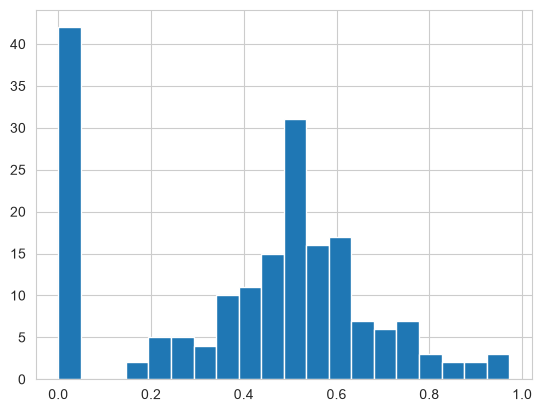

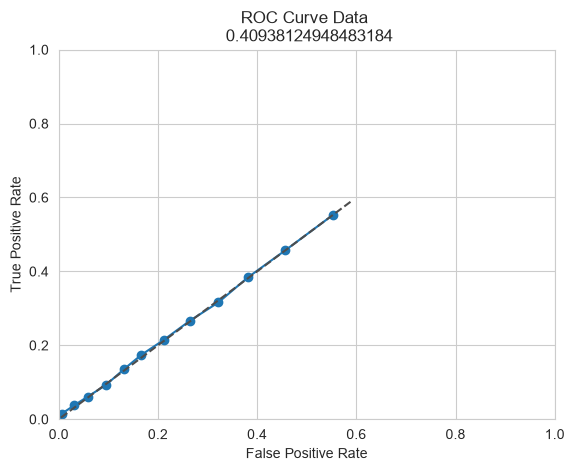

ValueError for RXRA: y_true contains only one label (0). Log-loss is not defined in that case.
ValueError for TBX5: y_true contains only one label (0). Log-loss is not defined in that case.
ValueError for VDR: y_true contains only one label (0). Log-loss is not defined in that case.
ValueError for NR3C1: y_true contains only one label (0). Log-loss is not defined in that case.
ValueError for NFIC: y_true contains only one label (0). Log-loss is not defined in that case.
ValueError for MEF2A: y_true contains only one label (0). Log-loss is not defined in that case.
ValueError for HOXA2: y_true contains only one label (0). Log-loss is not defined in that case.
ValueError for FOXA2: y_true contains only one label (0). Log-loss is not defined in that case.
ValueError for GFI1B: y_true contains only one label (0). Log-loss is not defined in that case.
ValueError for MECOM: y_true contains only one label (0). Log-loss is not defined in that case.
ValueError for IKZF1: y_true contains only on

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

... (179 outputs left out)

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [27]:
# TODO choice: I used held-out WT cells as my test set.
wt_val_dir = op.join(VAL_DIR, "wt_test")
os.makedirs(wt_val_dir, exist_ok=True)

validation, tprs_all, fprs_all, area_all = bb.tl.fit_validation(
    data_test,
    data_test_t1=None,
    nodes=nodes,
    regulators_dict=regulators_dict,
    rules=rules,
    save=True,
    save_dir=wt_val_dir,
    plot=True,
    show_plots=False,
    save_df=True,
)

bb.tl.save_auc_by_gene(area_all, nodes, wt_val_dir)
bb.plot.plot_aucs(wt_val_dir, save=True, show_plot=True)
bb.plot.plot_validation_avgs(
    fprs_all, tprs_all, len(nodes), area_all,
    save=True, save_dir=wt_val_dir, show_plot=True,
)

summary_stats = bb.tl.get_sklearn_metrics(wt_val_dir)
bb.plot.plot_sklearn_metrics(wt_val_dir)

In [29]:
# TODO choice: I saved the fitted WT network in my Stage 18 run folder.
G, edge_weight_df, edge_binary_df = bb.plot.draw_grn(
    graph,
    vertex_dict,
    rules,
    regulators_dict,
    op.join(RUN_DIR, "network.pdf"),
    save_edge_weights=True,
    edge_weights_fname=op.join(RUN_DIR, "rules", "edge_weights.csv"),
)

In [30]:
# TODO choice: I fit the Stage 18 mutant cells using the same candidate network as WT.
mutant_dir = op.join(RUN_DIR, "mutant")
mutant_plot_dir = op.join(mutant_dir, "rules", "rule_plots")
os.makedirs(mutant_plot_dir, exist_ok=True)

mutant_rules, mutant_regulators, mutant_strengths, mutant_signed_strengths = (
    bb.tl.get_rules(
        data=data_mutant,
        vertex_dict=vertex_dict,
        plot=True,
        show_plot=False,
        save_plot=True,
        save_dir=mutant_plot_dir,
        threshold=0,
    )
)

bb.tl.save_rules(
    mutant_rules, mutant_regulators, fname=op.join(mutant_dir, "rules.txt"),
)
mutant_strengths.to_csv(op.join(mutant_dir, "rules", "strengths.csv"))
mutant_signed_strengths.to_csv(
    op.join(mutant_dir, "rules", "signed_strengths.csv"),
)

print("Mutant rules fitted:", len(mutant_rules))

Fitting  0 / 188 rules
HINFP
0
...checking if FOXC1 is irrelevant
...checking if AR is irrelevant
...checking if TCF4 is irrelevant
...checking if MITF is irrelevant
...checking if NRF1 is irrelevant
...checking if HIF1A is irrelevant
Fitting  1 / 188 rules
SOX11
0
...checking if SOX2 is irrelevant
...checking if TFAP2A is irrelevant
...checking if BACH1 is irrelevant
...checking if MAX is irrelevant
...checking if KLF13 is irrelevant
...checking if SALL4 is irrelevant
Fitting  2 / 188 rules
RUNX2
0
...checking if NFKB1 is irrelevant
...checking if TCF4 is irrelevant
...checking if MYCN is irrelevant
...checking if MTF1 is irrelevant
...checking if SOX2 is irrelevant
...checking if MYBL2 is irrelevant
Fitting  3 / 188 rules
CLOCK
0
...checking if STAT3 is irrelevant
...checking if FOXC1 is irrelevant
...checking if TCF4 is irrelevant
...checking if NFIB is irrelevant
...checking if MYCN is irrelevant
...checking if TFAP2A is irrelevant
Fitting  4 / 188 rules
POU3F2
0
...checking if ZNF

In [31]:
# TODO choice: I used the fitted mutant rules to draw my Stage 18 mutant GRN.
mutant_G, mutant_edge_weight_df, mutant_edge_binary_df = bb.plot.draw_grn(
    graph,
    vertex_dict,
    mutant_rules,
    mutant_regulators,
    op.join(mutant_dir, "network.pdf"),
    save_edge_weights=True,
    edge_weights_fname=op.join(mutant_dir, "rules", "edge_weights.csv"),
)

In [32]:
import pandas as pd

wt_signed = pd.read_csv(
    op.join(RUN_DIR, "rules", "signed_strengths.csv"), index_col=0,
)
mutant_signed = pd.read_csv(
    op.join(mutant_dir, "rules", "signed_strengths.csv"), index_col=0,
)

print("WT — PAX6 as a regulator")
display(wt_signed[["PAX6"]].dropna())

print("Mutant — PAX6 as a regulator")
display(mutant_signed[["PAX6"]].dropna())

WT — PAX6 as a regulator


,PAX6
IRF9,0.636228
RXRA,-0.463602
CEBPE,-0.230946


Mutant — PAX6 as a regulator


,PAX6
IRF9,-1.441907
RXRA,-0.541271
CEBPE,-2.331178


In [33]:
import pandas as pd

wt_signed = pd.read_csv(
    op.join(RUN_DIR, "rules", "signed_strengths.csv"),
    index_col=0,
)

mutant_signed = pd.read_csv(
    op.join(mutant_dir, "rules", "signed_strengths.csv"),
    index_col=0,
)

candidate_edges = pd.read_csv(
    op.join(RUN_DIR, "network_for_fitting.csv"),
    header=None,
    names=["Regulator", "Target"],
)

# TODO choice: I focused on edges going into or out of PAX6.
print("Shared candidate edges involving PAX6")
display(candidate_edges.loc[
    candidate_edges["Regulator"].eq("PAX6")
    | candidate_edges["Target"].eq("PAX6")
])

print("PAX6 → target genes")
display(pd.DataFrame({
    "WT": wt_signed["PAX6"],
    "Mutant": mutant_signed["PAX6"],
}).dropna(how="all"))

print("Other regulators → PAX6")
display(pd.DataFrame({
    "WT": wt_signed.loc["PAX6"],
    "Mutant": mutant_signed.loc["PAX6"],
}).dropna(how="all"))

Shared candidate edges involving PAX6


,Regulator,Target
74,PAX6,CEBPE
411,PAX6,IRF9
654,TBX3,PAX6
655,SALL4,PAX6
656,LEF1,PAX6
657,PPARD,PAX6
658,TFAP2A,PAX6
659,TCF3,PAX6
807,PAX6,RXRA


PAX6 → target genes


,WT,Mutant
IRF9,0.636228,-1.441907
RXRA,-0.463602,-0.541271
CEBPE,-0.230946,-2.331178


Other regulators → PAX6


,WT,Mutant
PPARD,-0.052595,-2.067239
TCF3,0.392218,0.057031
TBX3,1.373117,0.926301
SALL4,-0.366213,-0.965579
TFAP2A,-1.093648,-2.408926
LEF1,0.982881,0.977932
